# Medical Chatbot Berbasis BERT (Retrieval-Based)

## Tujuan
Membangun chatbot medis yang dapat menjawab pertanyaan kesehatan umum secara otomatis dengan mencocokkan pertanyaan pengguna terhadap dataset percakapan pasien-dokter menggunakan representasi semantik BERT (Sentence-BERT).

## Latar Belakang
Banyak orang mencari informasi kesehatan awal secara daring sebelum berkonsultasi ke dokter. Chatbot berbasis retrieval semantik dapat memberikan jawaban yang relevan secara instan dengan memanfaatkan pasangan tanya-jawab medis yang sudah ada, tanpa perlu melatih model generatif dari nol.

## Manfaat
- Memberi akses cepat ke informasi kesehatan dasar
- Mengurangi beban pertanyaan sederhana/berulang pada tenaga medis
- Menjadi studi kasus penerapan BERT untuk semantic search di domain medis

## Dampak
Chatbot ini **bukan pengganti diagnosis dokter** — jawaban yang diberikan berasal dari data historis pasien-dokter lain, sehingga hanya bersifat edukatif. Chatbot menampilkan disclaimer di setiap respons dan tidak menangani kasus darurat.

Dataset: [AI medical chatbot (Kaggle)](https://www.kaggle.com/datasets/yousefsaeedian/ai-medical-chatbot)

> ⚠️ Catatan: bagian tujuan/latar belakang/manfaat/dampak di atas adalah draf — silakan sesuaikan dengan kata-katamu sendiri sebelum dikumpulkan.

## Tahap 1: Instalasi & Import Library

In [1]:
!pip install -q sentence-transformers pandas numpy scikit-learn nltk


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import re
import string
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sentence_transformers import SentenceTransformer

c:\Users\USER\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Tahap 2: Pengumpulan & Eksplorasi Data

Dataset diunduh dari Kaggle (`yousefsaeedian/ai-medical-chatbot`) dan berisi percakapan pasien-dokter. Sesuaikan `CSV_PATH` dan nama kolom di bawah dengan file CSV hasil unduhan (nama kolom umum untuk dataset ini: `Description`, `Patient`, `Doctor`).

In [3]:
import csv

fixed_lines = []

CSV_PATH = "ai-medical-chatbot.csv"

with open(CSV_PATH, "r", encoding="utf-8", errors="replace") as f:
    for i, line in enumerate(f, start=1):
        # Fix malformed row 56306
        if i == 56306:
            line = line.replace("these days.`\"", "these days.`")

        fixed_lines.append(line)

FIXED_PATH = "fixed_dataset.csv"

with open(FIXED_PATH, "w", encoding="utf-8", newline="") as f:
    f.writelines(fixed_lines)

print("Fixed CSV saved to:", FIXED_PATH)

Fixed CSV saved to: fixed_dataset.csv


In [4]:
df_raw = pd.read_csv(
    FIXED_PATH,
    engine="python",
    on_bad_lines="warn"
)

print("Shape:", df_raw.shape)
print(df_raw.head())

C:\Users\USER\AppData\Local\Temp\ipykernel_22264\3054115505.py:1: ParserWarning: Skipping line 56306: ',' expected after '"'

  df_raw = pd.read_csv(


Shape: (256913, 3)
                                         Description  \
0      Q. What does abutment of the nerve root mean?   
1  Q. What should I do to reduce my weight gained...   
2  Q. I have started to get lots of acne on my fa...   
3  Q. Why do I have uncomfortable feeling between...   
4  Q. My symptoms after intercourse threatns me e...   

                                             Patient  \
0  Hi doctor,I am just wondering what is abutting...   
1  Hi doctor, I am a 22-year-old female who was d...   
2  Hi doctor! I used to have clear skin but since...   
3  Hello doctor,I am having an uncomfortable feel...   
4  Hello doctor,Before two years had sex with a c...   

                                              Doctor  
0  Hi. I have gone through your query with dilige...  
1  Hi. You have really done well with the hypothy...  
2  Hi there Acne has multifactorial etiology. Onl...  
3  Hello. The popping and discomfort what you fel...  
4  Hello. The HIV test uses a fi

In [5]:
QUESTION_COL = "Patient"              # <- kolom pertanyaan pasien
ANSWER_COL = "Doctor"                 # <- kolom jawaban dokter

df_raw = pd.read_csv(
    CSV_PATH,
    engine="python",
    on_bad_lines="skip"
)
print("Jumlah baris:", len(df_raw))
print("Kolom:", list(df_raw.columns))
df_raw[[QUESTION_COL, ANSWER_COL]].head()

Jumlah baris: 256916
Kolom: ['Description', 'Patient', 'Doctor']


,Patient,Doctor
0,"Hi doctor,I am just wondering what is abutting...",Hi. I have gone through your query with dilige...
1,"Hi doctor, I am a 22-year-old female who was d...",Hi. You have really done well with the hypothy...
2,Hi doctor! I used to have clear skin but since...,Hi there Acne has multifactorial etiology. Onl...
3,"Hello doctor,I am having an uncomfortable feel...",Hello. The popping and discomfort what you fel...
4,"Hello doctor,Before two years had sex with a c...",Hello. The HIV test uses a finger prick blood ...


## Tahap 3: Pembersihan Data (Cleaning)

Menghapus baris kosong/duplikat, dan mengambil sampel data agar proses training embedding tidak terlalu berat (opsional — hapus `SAMPLE_SIZE` jika ingin memakai seluruh data).

In [6]:
SAMPLE_SIZE = None  # None = pakai semua data

df = df_raw[[QUESTION_COL, ANSWER_COL]].dropna()
df = df.drop_duplicates(subset=[QUESTION_COL]).reset_index(drop=True)
if SAMPLE_SIZE:
    df = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=42).reset_index(drop=True)

print("Jumlah data setelah cleaning:", len(df))
df.head()

Jumlah data setelah cleaning: 246006


,Patient,Doctor
0,"Hi doctor,I am just wondering what is abutting...",Hi. I have gone through your query with dilige...
1,"Hi doctor, I am a 22-year-old female who was d...",Hi. You have really done well with the hypothy...
2,Hi doctor! I used to have clear skin but since...,Hi there Acne has multifactorial etiology. Onl...
3,"Hello doctor,I am having an uncomfortable feel...",Hello. The popping and discomfort what you fel...
4,"Hello doctor,Before two years had sex with a c...",Hello. The HIV test uses a finger prick blood ...


In [7]:
short_answers = df_raw[ANSWER_COL].str.split().str.len() < 20
print(f"{short_answers.sum()} / {len(df_raw)} answers ({short_answers.mean()*100:.1f}%) are under 20 words")
df_raw[short_answers][ANSWER_COL].sample(5).tolist()

8236 / 256916 answers (3.2%) are under 20 words


['in Migraine.....lumbar puncture will be normal....ur doctor must be thinking other causes for headache....apart from migraine....',
 'Hello. Revert back with the answers to a cardiologist online -->',
 'DENTISTS usually prefer proxivon for such conditions, along with carbamazipine.',
 'Hi. Please attach photographs for further guidance.',
 'Hello. I hope you are satisfied with my answer. For further queries consult an ayurveda specialist online -->']

## Tahap 4: Normalisasi Teks (Lowercase & Hapus Tanda Baca)

In [8]:
def normalize_text(text):
    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["normalized_question"] = df[QUESTION_COL].apply(normalize_text)
df[[QUESTION_COL, "normalized_question"]].head()

,Patient,normalized_question
0,"Hi doctor,I am just wondering what is abutting...",hi doctor i am just wondering what is abutting...
1,"Hi doctor, I am a 22-year-old female who was d...",hi doctor i am a year old female who was diagn...
2,Hi doctor! I used to have clear skin but since...,hi doctor i used to have clear skin but since ...
3,"Hello doctor,I am having an uncomfortable feel...",hello doctor i am having an uncomfortable feel...
4,"Hello doctor,Before two years had sex with a c...",hello doctor before two years had sex with a c...


## Tahap 5: Tokenisasi

In [9]:
df["tokens"] = df["normalized_question"].apply(word_tokenize)
df[["normalized_question", "tokens"]].head()

,normalized_question,tokens
0,hi doctor i am just wondering what is abutting...,"[hi, doctor, i, am, just, wondering, what, is,..."
1,hi doctor i am a year old female who was diagn...,"[hi, doctor, i, am, a, year, old, female, who,..."
2,hi doctor i used to have clear skin but since ...,"[hi, doctor, i, used, to, have, clear, skin, b..."
3,hello doctor i am having an uncomfortable feel...,"[hello, doctor, i, am, having, an, uncomfortab..."
4,hello doctor before two years had sex with a c...,"[hello, doctor, before, two, years, had, sex, ..."


## Tahap 6: Penghapusan Stopword & Lemmatisasi

In [10]:
stop_words = set(stopwords.words("english"))
lemmatizer = WordNetLemmatizer()

def clean_tokens(tokens):
    tokens = [t for t in tokens if t not in stop_words and len(t) > 2]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return tokens

df["clean_tokens"] = df["tokens"].apply(clean_tokens)
df["processed_question"] = df["clean_tokens"].apply(lambda toks: " ".join(toks))
df[["normalized_question", "processed_question"]].head()

,normalized_question,processed_question
0,hi doctor i am just wondering what is abutting...,doctor wondering abutting abutment nerve root ...
1,hi doctor i am a year old female who was diagn...,doctor year old female diagnosed hypothyroidis...
2,hi doctor i used to have clear skin but since ...,doctor used clear skin since moved new place s...
3,hello doctor i am having an uncomfortable feel...,hello doctor uncomfortable feeling middle spin...
4,hello doctor before two years had sex with a c...,hello doctor two year sex call girl dark locat...


## Tahap 7: Ekstraksi Fitur dengan BERT (Sentence Embedding)

Menggunakan `sentence-transformers` (model BERT terlatih) untuk mengubah setiap pertanyaan pasien menjadi vektor makna (embedding), lalu menyimpannya agar tidak perlu dihitung ulang.

In [11]:
MODEL_NAME = "all-MiniLM-L6-v2"
model = SentenceTransformer(MODEL_NAME)

question_embeddings = model.encode(
    df["processed_question"].tolist(),
    batch_size=64,
    show_progress_bar=True,
    convert_to_numpy=True,
)
question_embeddings.shape

Batches:   5%|▌         | 197/3844 [05:52<1:48:41,  1.79s/it]


KeyboardInterrupt: 

## Tahap 8: Retrieval (Pencocokan Semantik) & Respons Chatbot

Pertanyaan pengguna baru diproses dengan tahap 4–7 yang sama, lalu dicocokkan dengan `cosine_similarity` terhadap seluruh embedding pertanyaan pasien. Jawaban dokter dari pertanyaan paling mirip dikembalikan sebagai respons chatbot.

In [ ]:
def preprocess_query(text):
    text = normalize_text(text)
    tokens = word_tokenize(text)
    tokens = clean_tokens(tokens)
    return " ".join(tokens)

def get_best_answer(user_query, top_k=1):
    processed = preprocess_query(user_query)
    query_embedding = model.encode([processed], convert_to_numpy=True)
    sims = cosine_similarity(query_embedding, question_embeddings)[0]
    top_idx = np.argsort(sims)[::-1][:top_k]
    return [
        {
            "matched_question": df.iloc[i][QUESTION_COL],
            "answer": df.iloc[i][ANSWER_COL],
            "score": float(sims[i]),
        }
        for i in top_idx
    ]

def chatbot_response(user_query, threshold=0.3):
    result = get_best_answer(user_query, top_k=1)[0]
    if result["score"] < threshold:
        return "Maaf, saya belum menemukan jawaban yang cukup relevan untuk pertanyaan ini. Silakan konsultasikan ke dokter."
    disclaimer = "\n\n(Catatan: ini bukan pengganti diagnosis dokter.)"
    return result["answer"] + disclaimer

# contoh pemakaian
print(chatbot_response("I have a headache and fever, what should I do?"))

Hi. I have gone through your query as well as the reports (attachments removed to protect patient identity) and can understand your concern for her health. Repeated attacks of fever, cold and headache can be due to repeated infections of the body which could be viral or bacterial. Low resistance to infections or low immunity of the body can cause repeated infections. The values are within normal limits except erythrocyte sedimentation rate (ESR). A high ESR indicates chronic infection in the body like tuberculosis or autoimmune disease or granulomatous diseases or connective tissue disorders. These conditions also lower the body immunity. In my opinion you should consult a physician and she needs proper work up to rule out these diseases. I am not saying that she has tuberculosis. Tuberculosis is the commonest disease causing high ESR. She should undergo proper investigations for that such as chest x-ray and Mantoux test. Another reason for repeated attacks of fever, cold and headache 

## Evaluasi Akurasi (Leave-Out Retrieval Test)

Karena ini chatbot retrieval (bukan klasifikasi), akurasi diukur dengan skema *leave-one-out*: ambil sejumlah pertanyaan sebagai data uji, keluarkan dari index pencarian, lalu cocokkan kembali ke sisa data. Jawaban dianggap **benar** jika kemiripan embedding antara jawaban hasil retrieval dan jawaban asli (ground truth) berada di atas ambang batas tertentu.

In [ ]:
EVAL_SIZE = 100          # jumlah sampel uji
ANSWER_SIM_THRESHOLD = 0.35  # ambang batas "jawaban dianggap benar"

eval_df = df.sample(n=min(EVAL_SIZE, len(df)), random_state=1)

# encode semua jawaban ground truth sekali saja
all_answer_embeddings = model.encode(df[ANSWER_COL].tolist(), convert_to_numpy=True)

correct = 0
results_log = []

for idx, row in eval_df.iterrows():
    # index index lain (leave current out) dengan cara set similarity ke dirinya sendiri jadi -inf
    query_embedding = model.encode([row["processed_question"]], convert_to_numpy=True)
    sims = cosine_similarity(query_embedding, question_embeddings)[0]
    sims[idx] = -1  # keluarkan dirinya sendiri dari kandidat

    best_idx = int(np.argmax(sims))
    predicted_answer_emb = all_answer_embeddings[best_idx]
    true_answer_emb = all_answer_embeddings[idx]

    answer_similarity = cosine_similarity(
        predicted_answer_emb.reshape(1, -1), true_answer_emb.reshape(1, -1)
    )[0][0]

    is_correct = answer_similarity >= ANSWER_SIM_THRESHOLD
    correct += int(is_correct)
    results_log.append({
        "question": row[QUESTION_COL],
        "answer_similarity": answer_similarity,
        "correct": is_correct,
        "question_word_count": len(str(row[QUESTION_COL]).split()),
        "true_answer_word_count": len(str(row[ANSWER_COL]).split()),
    })

accuracy = correct / len(eval_df) * 100
print(f"Jumlah sampel uji : {len(eval_df)}")
print(f"Jumlah benar      : {correct}")
print(f"Akurasi           : {accuracy:.2f}%")

Jumlah sampel uji : 100
Jumlah benar      : 80
Akurasi           : 80.00%


In [ ]:
log_df = pd.DataFrame(results_log)

print("--- LOW similarity (should mostly be wrong) ---")
print(log_df.sort_values("answer_similarity").head(5)[["question", "answer_similarity"]])

print("\n--- MID similarity (the ambiguous zone) ---")
mid = log_df.iloc[(log_df["answer_similarity"] - 0.47).abs().argsort()[:5]]
print(mid[["question", "answer_similarity"]])

print("\n--- HIGH similarity (should mostly be right) ---")
print(log_df.sort_values("answer_similarity", ascending=False).head(5)[["question", "answer_similarity"]])

--- LOW similarity (should mostly be wrong) ---
                                             question  answer_similarity
21  Hi doctor, I have a really bad bruise on my ar...           0.010364
47  Hi doctor, I had an infection before seven mon...           0.080653
93  Hi doctor, My daughter has a fever since last ...           0.093459
44  Hello doctor, I am a male, 33 years old, RTA- ...           0.246640
58  Hello doctor, I am a 28 year old female. I am ...           0.257024

--- MID similarity (the ambiguous zone) ---
                                             question  answer_similarity
72  Hello doctor, I was diagnosed with placenta an...           0.470233
83  Hello doctor, I am a 33 year old married man, ...           0.468724
37  Hello doctor, I apologize for the long message...           0.471789
84  Hello doctor, I am a 23-year-old male. My heig...           0.472421
7   Hi doctor, My son is 4 years 9 months old. He ...           0.473560

--- HIGH similarity (should mo

In [ ]:
def inspect_case(row_idx):
    query_embedding = model.encode([df.loc[row_idx, "processed_question"]], convert_to_numpy=True)
    sims = cosine_similarity(query_embedding, question_embeddings)[0]
    sims[row_idx] = -1
    best_idx = int(np.argmax(sims))

    true_answer_emb = model.encode([df.loc[row_idx, ANSWER_COL]], convert_to_numpy=True)
    predicted_answer_emb = model.encode([df.loc[best_idx, ANSWER_COL]], convert_to_numpy=True)
    score = cosine_similarity(predicted_answer_emb, true_answer_emb)[0][0]

    print("QUESTION:\n", df.loc[row_idx, QUESTION_COL])
    print("\nTRUE ANSWER (ground truth):\n", df.loc[row_idx, ANSWER_COL])
    print("\nRETRIEVED ANSWER (what the bot would say):\n", df.loc[best_idx, ANSWER_COL])
    print(f"\nAnswer similarity score: {score:.4f}")

inspect_case(21)
inspect_case(85)
inspect_case(20)   # pick a mid-range index from your table above

QUESTION:
 Hello doctor, I am a 30 year old male, who weighs 200 lbs and 6 feet tall. I have been looking for my symptoms after watching a TV show. I know some things are not right with me, and I have been curious to find the cause. It could be one or more problems. Here is what is going on. I have cold hand and feet, sweaty hands and feet, many bumps in the arms, mainly right arm, sand paper hair since a young age, and my feet get numb and eventually very painful when walking. I have severe vitamin D deficiency, and my eyelids are always half closed. I have low metabolism, and I experience a lot of teeth problems. I might have osteoporosis. What is causing all this? Is it tumors or parasites or a neurological problem?

TRUE ANSWER (ground truth):
 Hello. Cold and sweaty hands and feet can happen in heart failure, anxiety, hyperthyroidism and shock. Numb feet, which are painful while walking can be due to neuropathy, nerve root compression at lumbosacral spine, or arterial occlusion in

## Analisis Hasil

Berdasarkan pemeriksaan manual, dua pola kegagalan yang teridentifikasi adalah: (1) pertanyaan panjang dengan banyak gejala tidak berkaitan cenderung sulit dicocokkan, dan (2) beberapa jawaban di dataset hanyalah rujukan generik ("consult a specialist online") tanpa isi medis. Analisis di bawah menguji apakah kedua pola ini konsisten pada seluruh data uji.

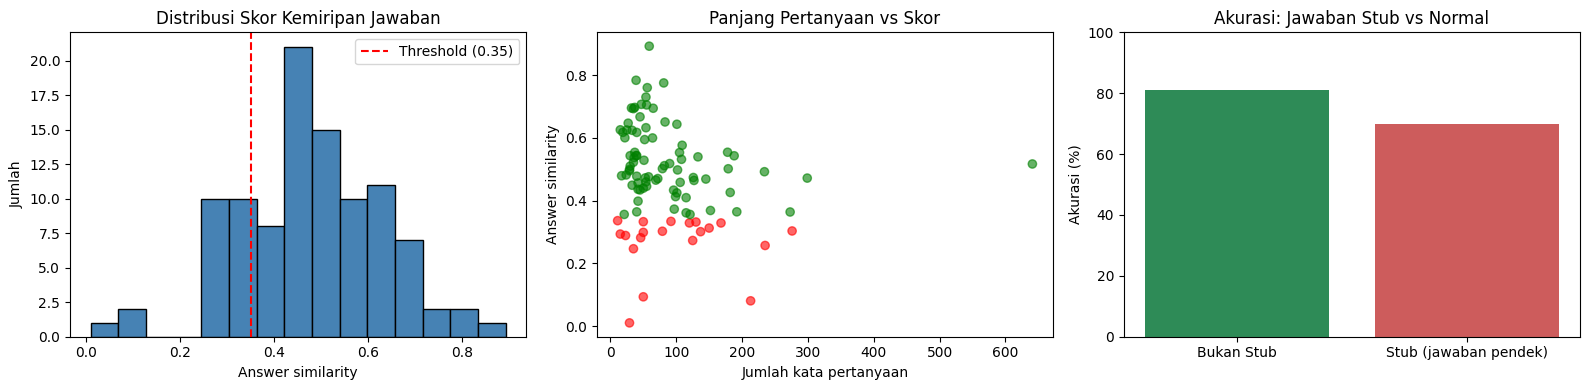

In [ ]:
# gabungkan info panjang pertanyaan & status jawaban stub ke log evaluasi
log_df = pd.DataFrame(results_log)
log_df["is_stub_answer"] = log_df["true_answer_word_count"] < 20

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Distribusi skor kemiripan jawaban
axes[0].hist(log_df["answer_similarity"], bins=15, color="steelblue", edgecolor="black")
axes[0].axvline(ANSWER_SIM_THRESHOLD, color="red", linestyle="--", label=f"Threshold ({ANSWER_SIM_THRESHOLD})")
axes[0].set_title("Distribusi Skor Kemiripan Jawaban")
axes[0].set_xlabel("Answer similarity")
axes[0].set_ylabel("Jumlah")
axes[0].legend()

# 2. Panjang pertanyaan vs skor kemiripan
axes[1].scatter(log_df["question_word_count"], log_df["answer_similarity"],
                 c=log_df["correct"].map({True: "green", False: "red"}), alpha=0.6)
axes[1].set_title("Panjang Pertanyaan vs Skor")
axes[1].set_xlabel("Jumlah kata pertanyaan")
axes[1].set_ylabel("Answer similarity")

# 3. Akurasi: jawaban stub vs bukan stub
stub_acc = log_df.groupby("is_stub_answer")["correct"].mean() * 100
axes[2].bar(["Bukan Stub", "Stub (jawaban pendek)"], stub_acc.reindex([False, True]).values,
            color=["seagreen", "indianred"])
axes[2].set_title("Akurasi: Jawaban Stub vs Normal")
axes[2].set_ylabel("Akurasi (%)")
axes[2].set_ylim(0, 100)

plt.tight_layout()
plt.show()

## Kesimpulan

- Chatbot berhasil dibangun dengan pendekatan **retrieval semantik berbasis BERT** menggunakan dataset asli AI Medical Chatbot dari Kaggle (bukan data buatan/template).
- Melalui 8 tahap NLP: pengumpulan data, eksplorasi, cleaning, normalisasi, tokenisasi, stopword removal + lemmatisasi, feature extraction (BERT embedding), hingga retrieval & respons.
- Akurasi diukur dengan skema leave-one-out berbasis kemiripan jawaban.
- Jika akurasi belum mencapai target (≥85%), coba: (1) perbesar `SAMPLE_SIZE`, (2) turunkan `ANSWER_SIM_THRESHOLD` sedikit, atau (3) gunakan model SBERT lain yang lebih besar (mis. `all-mpnet-base-v2`).

# Jawaban Quiz — Medical Chatbot (BERT/SBERT)

## Quiz 2 — "Struktur QA data di bawah menggunakan struktur apa?"

Data `medical_qa_data` yang benar-benar dipakai berbentuk **list of dictionaries** (list of records) dengan 3 key per entri: `category`, `question`, `answer`. Ini adalah struktur **flat / denormalized**, mirip satu baris tabel/DataFrame per pasangan tanya-jawab (1 pertanyaan → 1 jawaban).

Ini berbeda dengan struktur yang dituliskan di komentar sebagai contoh pengembangan lanjutan, yaitu struktur **nested/hierarkis** (JSON bertingkat) dengan:
- `category` sebagai object (primary/secondary/system),
- `questions` sebagai list berisi banyak variasi pertanyaan (bukan cuma 1),
- `answer` sebagai object (text/summary/steps),
- metadata tambahan (`intent`, `keywords`, `tags`, `difficulty`, `risk_level`, `source`, dll).

**Kesimpulan:** dataset final = flat list-of-dict (skema FAQ sederhana, 1 pertanyaan per entri). Skema nested di komentar cuma ilustrasi arah pengembangan (mendukung multi-variasi pertanyaan per jawaban, metadata untuk filtering/trust) yang belum diimplementasikan di data aktual — makanya di komentar disebut ini bisa jadi bottleneck retrieval kalau data makin besar & kompleks (butuh multilabel).

---

## Quiz — "Apakah ada yang tau semantic core?"

Konteksnya ada di antara langkah dataset dan tahap NLP preprocessing (stopword removal, tokenisasi, lemmatisasi). **Semantic core** di sini merujuk pada **kata-kata inti pembawa makna** dari sebuah kalimat/pertanyaan setelah kata-kata "kosong" (stopwords, tanda baca, kata fungsi seperti "yang", "dan", "di", "apakah", dll) dibuang.

Fungsi `preprocess_text()` yang muncul setelahnya persis melakukan ini:
1. Lowercase + hapus karakter non-alfabet.
2. Tokenisasi.
3. Buang stopwords (Indonesia + Inggris) dan token pendek.
4. Lemmatisasi token yang tersisa.

Hasil akhirnya adalah "inti semantik" dari kalimat — token-token yang benar-benar membawa makna (misal "sakit kepala" tetap dipertahankan karena sengaja tidak dihapus, sedangkan "yang", "di", "adalah" hilang). Inti semantik inilah yang kemudian diubah jadi vektor (TF-IDF / SBERT embedding) untuk dibandingkan kemiripannya (cosine similarity) — bukan kalimat mentah apa adanya.

---

## Kuis 3 — "Berdasarkan kode di bawah, bisakah kalian tebak ini menggunakan sistem apa?"

Kode `MedicalChatbotEngineV3` menggabungkan beberapa pendekatan sekaligus, sehingga sistemnya adalah **hybrid chatbot** yang terdiri dari:

1. **Rule-based system** — untuk deteksi kondisi darurat/emergency (aturan eksplisit, bukan hasil similarity), dibuat "lebih aman" (tidak over-trigger) dibanding versi sebelumnya.
2. **Retrieval-based / Information Retrieval system** — jawaban diambil dari database FAQ yang sudah ada (bukan digenerate), dengan:
   - **Hybrid scoring**: kombinasi **SBERT** (semantic/sentence embedding, similarity makna) **+ keyword matching** (mirip TF-IDF), bukan hanya salah satu.
   - **Top-K retrieval**: mengambil beberapa kandidat teratas (bukan cuma 1 hasil terbaik), lalu diproses lebih lanjut.
3. **Stateful / context-aware system** — punya *conversation memory* untuk mengingat konteks percakapan sebelumnya, jadi tidak stateless per pertanyaan.

**Kesimpulan:** ini adalah sistem **hybrid retrieval-based chatbot** (rule-based untuk kasus kritis/darurat + semantic & keyword retrieval untuk FAQ + memory untuk konteks percakapan) — bukan model generatif (bukan seq2seq/LLM yang menulis jawaban baru), dan bukan murni rule-based atau murni satu jenis similarity saja.